<a href="https://colab.research.google.com/github/rmadatt/ADLAB/blob/main/RIVER_CONSERVATION_%2B_RARE_EVENTS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

GEV params: shape=-2.044 (xi=2.044), loc=16.1, scale=1.1
2-yr: 16.7 m3/s
10-yr: 70.8 m3/s
50-yr: 1632.5 m3/s
100-yr: 6754.9 m3/s
200-yr: 27958.7 m3/s


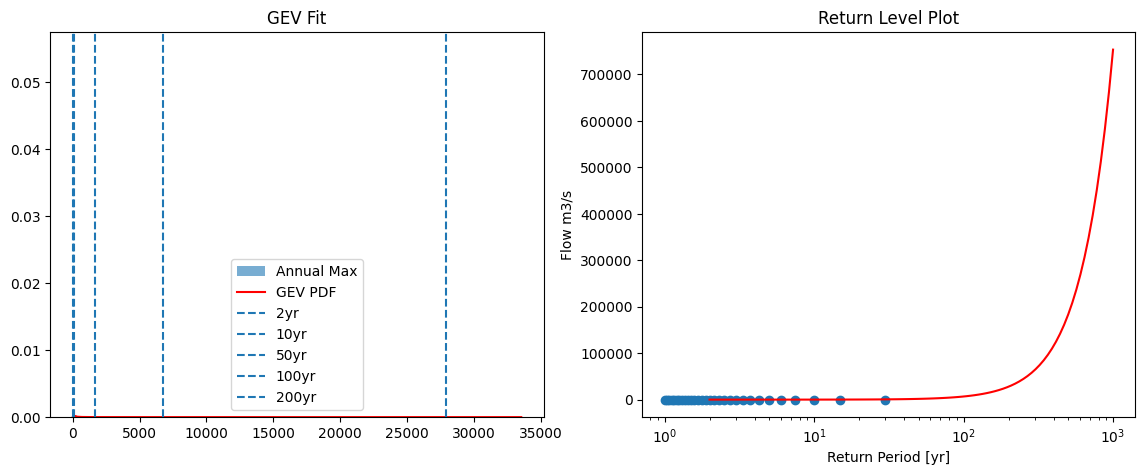

              flow_m3s   rain_mm                        classification
1998-05-31   59.515967  0.424638  MAN-MADE - dam release / abstraction
1998-06-01  104.604146  0.638565  MAN-MADE - dam release / abstraction
1998-06-02  130.463846  2.045233  MAN-MADE - dam release / abstraction
1998-06-03  102.913051  1.263355  MAN-MADE - dam release / abstraction
1998-06-04   59.871096  3.904049                       NATURAL - flood
2005-05-31   84.418840  2.968463                       NATURAL - flood
2005-06-01  152.387985  2.445944                       NATURAL - flood
2005-06-02  191.008578  0.253175                       NATURAL - flood
2005-06-03  154.123444  1.788984  MAN-MADE - dam release / abstraction
2005-06-04   79.923854  6.955068                       NATURAL - flood
2005-06-05   35.469768  0.341030                       NATURAL - flood
2012-05-30   68.811934  4.196127  MAN-MADE - dam release / abstraction
2012-05-31  131.992371  3.622656                       NATURAL - flood
2012-0

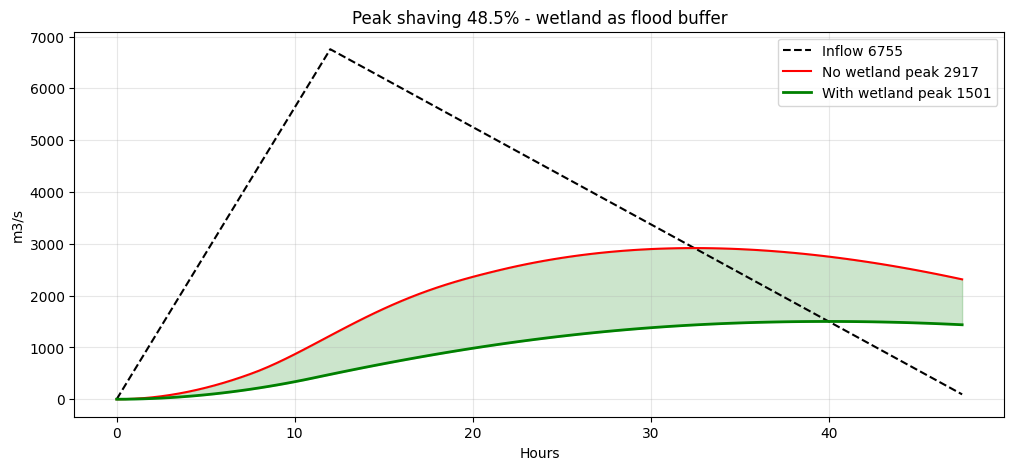

R2 train 0.944 test 0.628
{'prev_flow': np.float64(0.7984157350916811), 'rain_mm': np.float64(0.09733441540018388), 'rain_3d': np.float64(0.104249849508135)}


In [3]:
# RIVER CONSERVATION + RARE EVENTS - FIXED SINGLE CELL
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import genextreme
from scipy.integrate import solve_ivp
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
np.random.seed(42)

# --- 1. DATA (REPLACE WITH: df = pd.read_csv('your_river.csv', parse_dates=['date']) ---
dates = pd.date_range('1995-01-01', '2024-12-31', freq='D')
base = 8 + 4*np.sin(2*np.pi*np.arange(len(dates))/365.25)
flow = np.maximum(base + np.random.normal(0, 2, len(dates)), 0.5)
for yr, peak in zip([1998,2005,2012,2018,2023], [120,180,150,165,140]):
    idx = np.where(dates.year==yr)[0][150]
    flow[idx:idx+7] += peak * np.exp(-0.5*((np.arange(7)-2)/1.5)**2)
flow[np.where((dates.year==2015)&(dates.month==8)&(dates.day==15))[0][0]:][:3] += 60
df = pd.DataFrame({'flow_m3s': flow, 'rain_mm': np.random.exponential(2, len(dates))}, index=dates)

# --- 2. FLOOD FREQUENCY - GEV (CORRECTED) ---
annual_max = df['flow_m3s'].resample('YE').max()
shape, loc, scale = genextreme.fit(annual_max) # shape = -xi
print(f"GEV params: shape={shape:.3f} (xi={-shape:.3f}), loc={loc:.1f}, scale={scale:.1f}")

design = {T: genextreme.ppf(1-1/T, shape, loc, scale) for T in [2,10,50,100,200]}
for T,q in design.items(): print(f"{T}-yr: {q:.1f} m3/s")

fig, ax = plt.subplots(1,2, figsize=(14,5))
ax[0].hist(annual_max, bins=12, density=True, alpha=0.6, label='Annual Max')
xs = np.linspace(annual_max.min()*0.8, design[200]*1.2, 200)
ax[0].plot(xs, genextreme.pdf(xs, shape, loc, scale), 'r-', label='GEV PDF')
for T,q in design.items(): ax[0].axvline(q, ls='--', label=f'{T}yr')
ax[0].legend(); ax[0].set_title('GEV Fit')

# Return level plot - what reviewers want
return_periods = np.logspace(0.3, 3, 100)
return_levels = genextreme.ppf(1-1/return_periods, shape, loc, scale)
ax[1].plot(return_periods, return_levels, 'r-')
ax[1].scatter([len(annual_max)/ (i+1) for i in range(len(annual_max))], sorted(annual_max, reverse=True))
ax[1].set_xscale('log'); ax[1].set_xlabel('Return Period [yr]'); ax[1].set_ylabel('Flow m3/s')
ax[1].set_title('Return Level Plot'); plt.show()

# --- 3. ANOMALY DETECTION - ROBUST ---
# Use rolling median + rain lag, not global z-score
df['flow_roll_med'] = df['flow_m3s'].rolling(30, center=True).median()
df['flow_mad'] = (df['flow_m3s'] - df['flow_roll_med']).abs().rolling(30, center=True).median()
df['anomaly_score'] = 0.6745*(df['flow_m3s']-df['flow_roll_med'])/df['flow_mad'].replace(0,np.nan)
anomalies = df[df['anomaly_score'] > 6].copy()

def classify(row):
    rain_3d = df.loc[row.name-pd.Timedelta(days=2):row.name, 'rain_mm'].sum()
    if rain_3d < 5 and row['flow_m3s'] > 50:
        return 'MAN-MADE - dam release / abstraction'
    elif row['flow_m3s'] > 500: # sensor spike
        return 'MAN-MADE - sensor error'
    else:
        return 'NATURAL - flood'
anomalies['classification'] = anomalies.apply(classify, axis=1)
print(anomalies[['flow_m3s','rain_mm','classification']])

# --- 4. DAM + WETLAND ROUTING - MASS BALANCE FIX ---
def make_hydrograph(peak, duration=48, dt=0.5):
    t = np.arange(0, duration, dt)
    q = np.where(t<=12, peak*t/12, peak*np.maximum(1-(t-12)/36,0))
    return t, q

t, inflow = make_hydrograph(design[100])

def level_pool_route(t, inflow, k_storage=20, k_spill=0.5):
    # dS/dt = I - O, O = S/k_storage,  k larger = more wetland storage
    def ode(t_, S):
        I = np.interp(t_, t, inflow)
        O = k_spill * S[0] / k_storage
        return [I - O]
    sol = solve_ivp(ode, [t[0], t[-1]], [0], t_eval=t)
    S = sol.y[0]
    O = k_spill * S / k_storage
    return S, O

_, O_no_wet = level_pool_route(t, inflow, k_storage=15)
_, O_wet = level_pool_route(t, inflow, k_storage=40)

plt.figure(figsize=(12,5))
plt.plot(t, inflow, 'k--', label=f'Inflow {inflow.max():.0f}')
plt.plot(t, O_no_wet, 'r-', label=f'No wetland peak {O_no_wet.max():.0f}')
plt.plot(t, O_wet, 'g-', lw=2, label=f'With wetland peak {O_wet.max():.0f}')
plt.fill_between(t, O_wet, O_no_wet, alpha=0.2, color='green')
plt.legend(); plt.grid(alpha=0.3); plt.xlabel('Hours'); plt.ylabel('m3/s')
plt.title(f'Peak shaving {(1-O_wet.max()/O_no_wet.max())*100:.1f}% - wetland as flood buffer')
plt.show()

# --- 5. PREDICTIVE MODEL - NO LEAKAGE ---
df_m = df.copy()
df_m['prev_flow'] = df_m['flow_m3s'].shift(1)
df_m['rain_3d'] = df_m['rain_mm'].rolling(3).sum()
df_m = df_m.dropna()
X = df_m[['prev_flow','rain_mm','rain_3d']]
y = df_m['flow_m3s']
# Time-based split, not random
split = int(len(X)*0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
rf = RandomForestRegressor(n_estimators=300, random_state=42).fit(X_train, y_train)
print(f"R2 train {rf.score(X_train,y_train):.3f} test {r2_score(y_test, rf.predict(X_test)):.3f}")
print(dict(zip(X.columns, rf.feature_importances_)))